In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import diffrax as dfx

# jax.config.update("jax_disable_jit",True)
jax.local_device_count()

import numpy as np
import matplotlib.pyplot as plt
import arviz as az
import ICIW_Plots
import xarray

from ipywidgets import Dropdown, interact, IntSlider

plt.style.use("ICIWstyle")

In [2]:
from HSA_Mo_B_011 import (
    kinetics_model,
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    validate_against_holdout,
    sample_prior,
    TRUE_PARAMS,
)

In [3]:
exp_run_name = "shivering-whale"
data_path = Path(f"data/{exp_run_name}/seed042")
sum_file = data_path / f"experiment_summary.json"
trace_files = sorted(data_path.glob("trace_*.nc"))

In [4]:
idatas = []
for trace_file in trace_files:
    idata = az.from_netcdf(trace_file)
    idatas.append(idata)

In [5]:
for i, idata in enumerate(idatas):
    if i == 0:
        idata.update(xarray.DataTree.from_dict({"prior": sample_prior(4000).prior}))
    else:
        idata.update(
            xarray.DataTree.from_dict({"prior": idatas[i - 1]["posterior"].dataset})
        )

In [6]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)

In [7]:
proposals = np.array(exp_summary["trials"][-1]["observed"]["x"])
r_obs = np.array(exp_summary["trials"][-1]["observed"]["y"])

In [8]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])
    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range for evaluation
    T = jnp.linspace(450.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range
    T = jnp.linspace(450.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(
        T, p, c2h, c2m, c2w, c2i, rel_noise_std=0.0
    )

    return true_rates


def plot_predictions(fig, ax, proposal, posterior_preds, true_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # True model
    ax.plot(
        T_range,
        true_preds.squeeze(),
        label="True Model",
        color="black",
        linestyle="--",
        linewidth=2,
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    ax.legend(loc="upper left")

    # Add condition text
    # condition_text = (
    #     f"Conditions:\n"
    #     f"p = {proposal[1]:.1f} bar\n"
    #     f"CO2/H2 = {proposal[2]:.2f}\n"
    #     f"Feed ratio = {proposal[3]:.1f}\n"
    #     f"CO2/Inert = {proposal[4]:.2f}"
    # )
    # ax.text(
    #     0.02,
    #     0.8,
    #     condition_text,
    #     transform=ax.transAxes,
    #     fontsize=9,
    #     verticalalignment="top",
    #     bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5),
    # )

    # Second y-axis for HDI width
    # ax2 = ax.twinx()
    # hdi_width = np.percentile(posterior_preds, 97.5, axis=1) - np.percentile(
    #     posterior_preds, 2.5, axis=1
    # )
    # ax2.plot(T_range, hdi_width, color="orange", alpha=0.7, linewidth=2)
    # ax2.set_ylabel("HDI Width", color="orange")
    # ax2.tick_params(axis="y", labelcolor="orange")

    # plt.title("Posterior Predictions vs True Model")
    # plt.tight_layout()
    return fig, ax

# Exploration pattern

/tmp/ipykernel_14836/2292498082.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


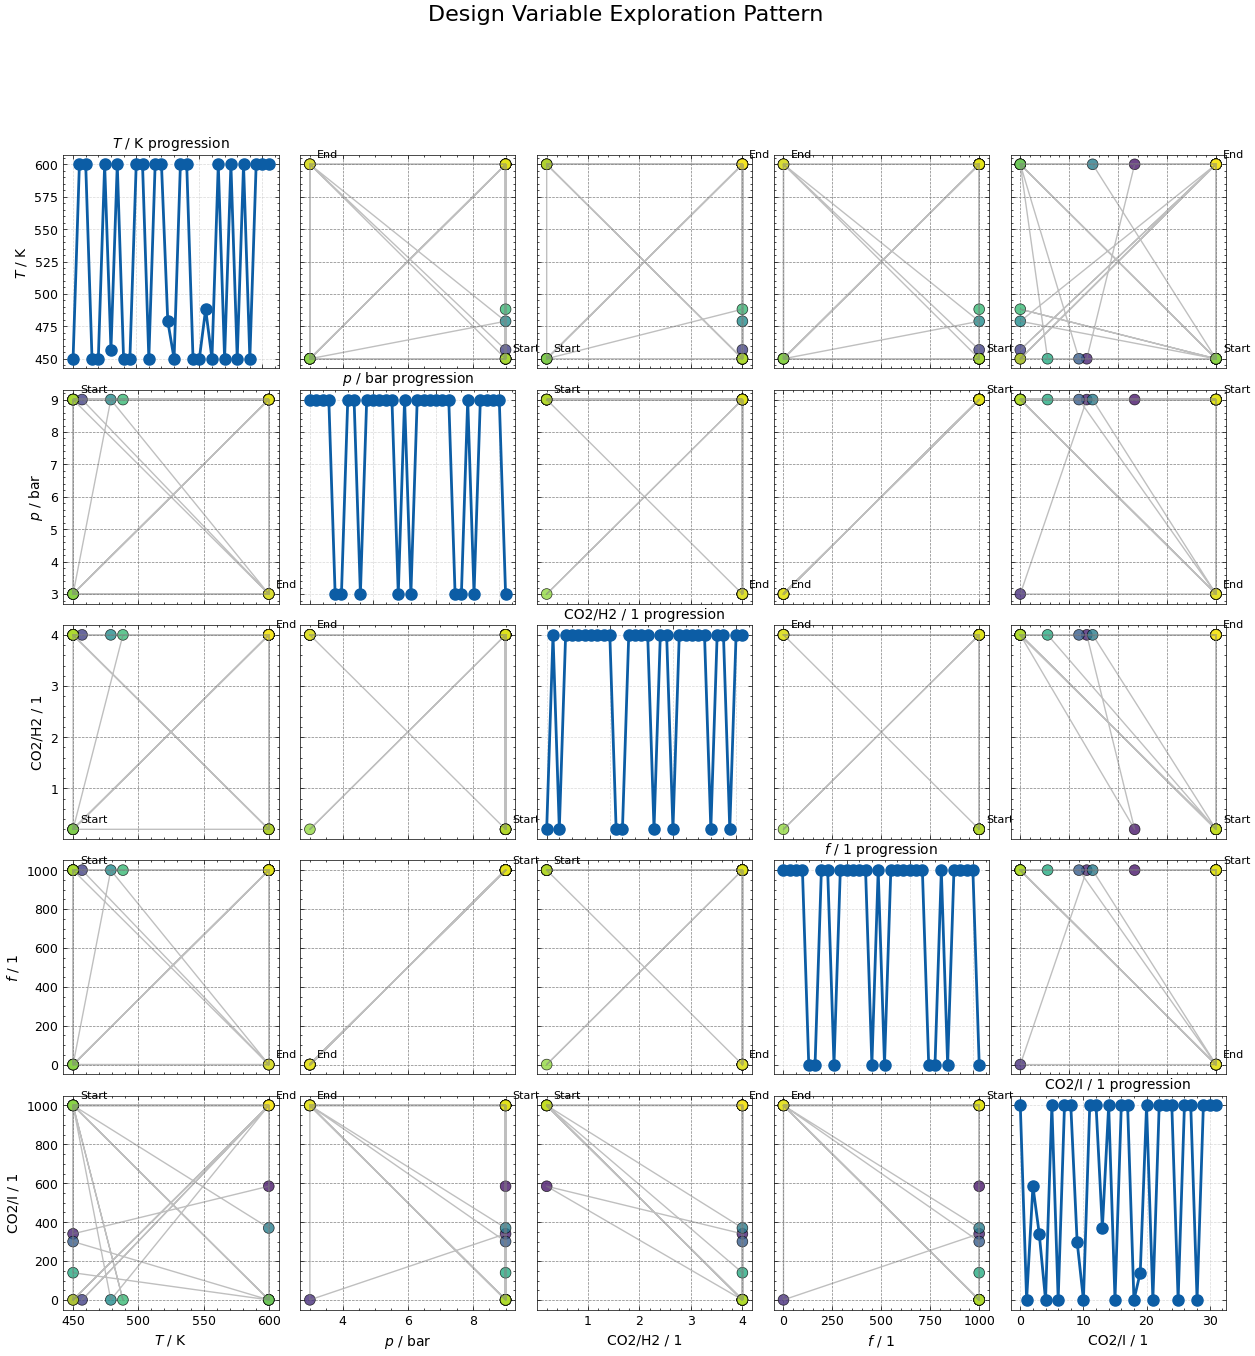

In [9]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = [r"$T$ / K", r"$p$ / bar", r"CO2/H2 / 1", r"$f$ / 1", r"CO2/I / 1"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

In [10]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$T$ / K",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
        yscale="log",
        # ylim=(5e-6, 5e-4),
        # xlim=(450, 600),
    )
    test_res = evaluate_conditions(
        proposal=proposals[j],
        idata=idatas[i],
        key="posterior" if i > 0 else "prior",
    )
    true_res = evaluate_true_model(
        proposal=proposals[j],
    )
    plot_predictions(
        fig,
        ax,
        proposal=proposals[j],
        posterior_preds=test_res,
        true_preds=true_res,
        T_range=np.linspace(450, 600, 100),
    )
    ax.scatter(
        proposals[j, 0], r_obs[j], color="red", label="Observed Data Point", zorder=5
    )
    plt.show()

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), IntSlider(value=0, description='Pr…

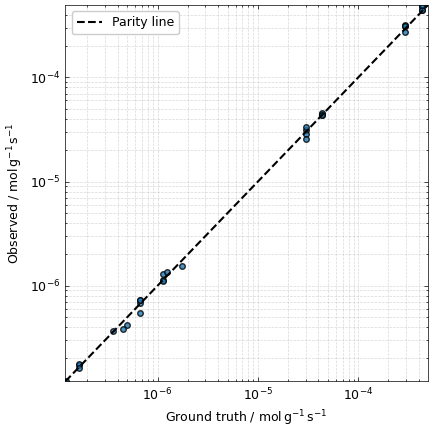

In [11]:
# Generate noiseless ground-truth rates at the observed experimental conditions
T_true = jnp.asarray(proposals[:, 0]).reshape(-1, 1)
p_true = jnp.asarray(proposals[:, 1]).reshape(-1, 1)
c2h_true = jnp.asarray(proposals[:, 2]).reshape(-1, 1)
c2m_true = jnp.asarray(proposals[:, 3]).reshape(-1, 1)
c2w_true = jnp.asarray(proposals[:, 4]).reshape(-1, 1)
c2i_true = jnp.asarray(proposals[:, 5]).reshape(-1, 1)

_, _, r_true = generate_synthetic_data(
    T_true,
    p_true,
    c2h_true,
    c2m_true,
    c2w_true,
    c2i_true,
    rel_noise_std=0.0,
)

r_true = np.asarray(r_true).squeeze()
r_observed = np.asarray(r_obs).squeeze()

fig, ax = plt.subplots(figsize=(4.5, 4.5))

ax.scatter(r_true, r_observed, color="tab:blue", edgecolor="black", alpha=0.8)

limits = [
    min(r_true.min(), r_observed.min()),
    max(r_true.max(), r_observed.max()),
]
ax.plot(limits, limits, "k--", label="Parity line")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_xlabel(r"Ground truth / $\mathrm{mol\,g^{-1}\,s^{-1}}$")
ax.set_ylabel(r"Observed / $\mathrm{mol\,g^{-1}\,s^{-1}}$")
ax.legend()
ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
plt.rcParams.update(
    {
        "font.size": 7,
        "figure.dpi": 300,
    },
)

In [13]:
@interact(
    i=IntSlider(
        min=0,
        max=len(idatas) - 1,
        step=1,
        value=0,
        description="Iteration:",
    ),
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    ),
)
def interactive(i, key):
    az.plot_prior_posterior(
        idatas[i],
        var_names=[key],
    )
    pass

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), Dropdown(description='Parameter:',…

In [14]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    data = az.extract(idatas[i], sample_dims="draw", num_samples=100)
    az.plot_pair(
        data,
        # group="posterior",
        var_names=["k0", "Ea_k", "A_oh", "dH_oh"],
        visuals={
            "point_estimate": {"color": "grey"},
        },
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), Output()), _dom_classes=('widget-i…

## The parameter values compared to GT

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:468: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:503: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")
/tmp/ipykernel_14836/3924509602.py:102: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


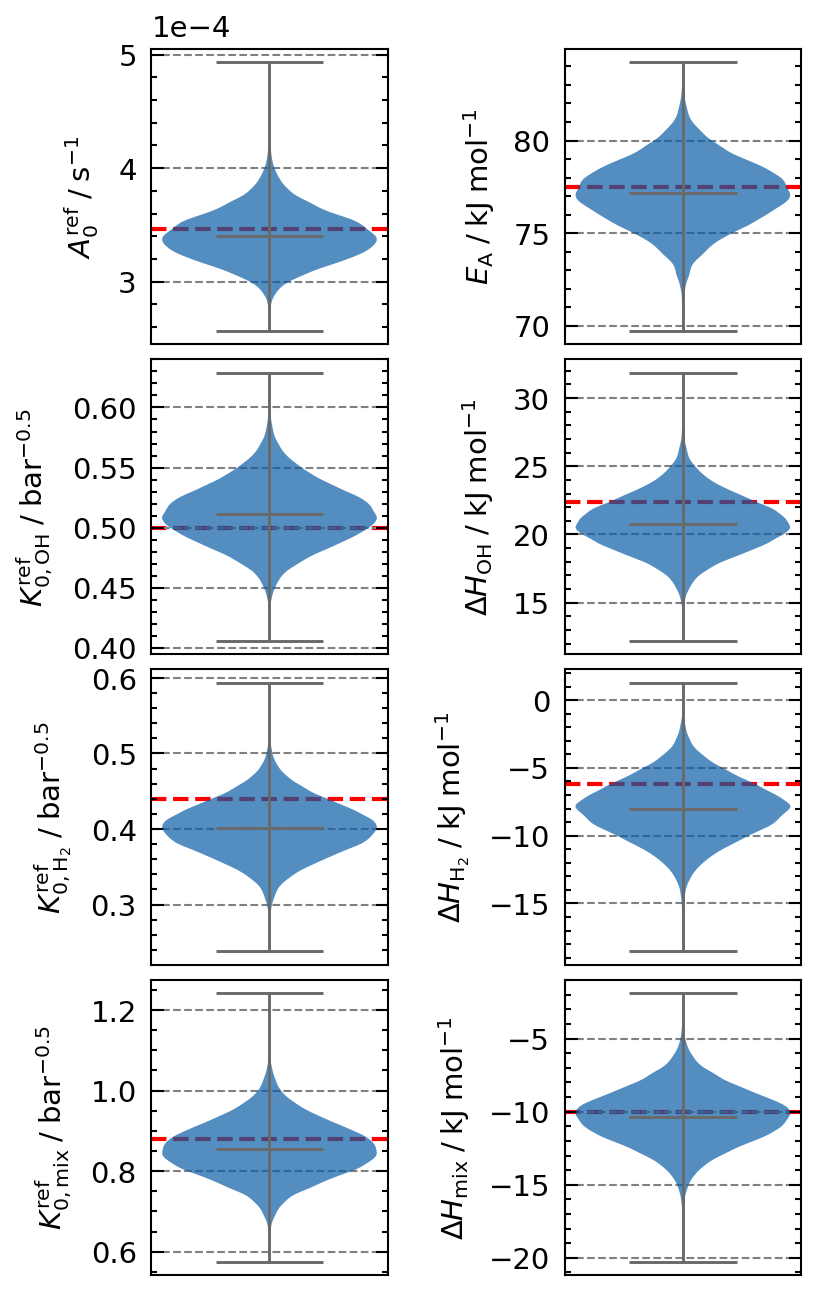

In [15]:
# fig, axes = plt.subplots(4, 2, figsize=(12, 16))
fig = ICIW_Plots.figure(layout="single_column", height=12 * ICIW_Plots.cm2inch)
axes = ICIW_Plots.make_rect_subplots(
    fig,
    ax_width=2.0 * ICIW_Plots.cm2inch,
    ax_layout=(4, 2),
    ax_height=2.5 * ICIW_Plots.cm2inch,
    h_sep=1.5 * ICIW_Plots.cm2inch,
    # sharex=True,
    left_h=1.5 * ICIW_Plots.cm2inch,
    bottom_v=1.2 * ICIW_Plots.cm2inch,
)
axes = axes.flatten()

param_names = ["k0", "Ea_k", "A_oh", "dH_oh", "A_h2", "dH_h2", "A_mix", "dH_mix"]

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}
labeldict = {
    "k0": r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$",
    "Ea_k": r"$E_\mathrm{A}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_oh": r"$K_{0,\mathrm{OH}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_oh": r"$\Delta H_\mathrm{OH}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_h2": r"$K_{0,\mathrm{H_2}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_h2": r"$\Delta H_\mathrm{H_2}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_mix": r"$K_{0,\mathrm{mix}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_mix": r"$\Delta H_\mathrm{mix}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
}

for idx, param in enumerate(param_names):
    ax = axes[idx]

    # Collect samples for each DOE method
    violin_data = []
    labels = []

    # Get final posterior samples for this parameter
    samples = idatas[-1].posterior[param].values.flatten()
    if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
        samples = samples * 1e-3  # Convert to kJ/mol for better readability
    violin_data = samples
    labels.append("")

    # Create violin plot
    parts = ax.violinplot(
        violin_data,
        showmeans=True,
        # showmedians=True,
        widths=0.7,
    )

    # Make violin lines thinner
    for partname in ("cbars", "cmins", "cmaxes", "cmeans", "cmedians"):
        if partname in parts:

            parts[partname].set_color("dimgrey")
            parts[partname].set_linewidth(0.7)

    # Color the violins
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for i, pc in enumerate(parts["bodies"]):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)
        # pc.set_linewidth(1.0)

    # Plot ground truth
    true_val = TRUE_PARAMS[keydict[param]]
    if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
        true_val = true_val * 1e-3  # Convert to kJ/mol for better readability
    ax.axhline(
        y=true_val,
        color="red",
        linestyle="--",
        linewidth=1.0,
        label="Ground Truth",
        zorder=0,
    )

    ax.set_ylabel(f"{labeldict[param]}")

    # Remove x-axis ticks and labels
    ax.set_xticks([])
    ax.set_xticklabels([])

    # Remove x-axis grid
    ax.grid(False, axis="x")

    # Adjust x-axis limits
    # ax.set_xlim(-0.5, len(ov) - 0.5)

axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))


plt.tight_layout()
plt.savefig("figures/KinFit_parameter_comparison.png")
plt.savefig("figures/KinFit_parameter_comparison.svg")
plt.savefig("figures/KinFit_parameter_comparison.pdf")
plt.show()

## The RMSE

In [16]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[var_name].values
    pred = postdata.posterior_predictive[var_name].values
    res = true - pred
    rmse_vals = np.sqrt(np.mean(res**2, axis=2)).squeeze()
    return rmse_vals


def calculate_RMSEs(valdatas):
    RMSEs = []
    for valdata in valdatas:
        rmse_da = bRMSE(valdata, "r_pred")
        RMSEs.append(rmse_da)
    return np.array(RMSEs)

In [17]:
test_data = xarray.open_dataset(Path("data/test_HSA_Da_B_001.nc"))

valdatas = []

for i, idata in enumerate(idatas):
    valdata = validate_against_holdout(
        idata,
        test_data,
        num_samples=5000,
    )
    valdatas.append(valdata)

In [18]:
RMSEs = calculate_RMSEs(valdatas)

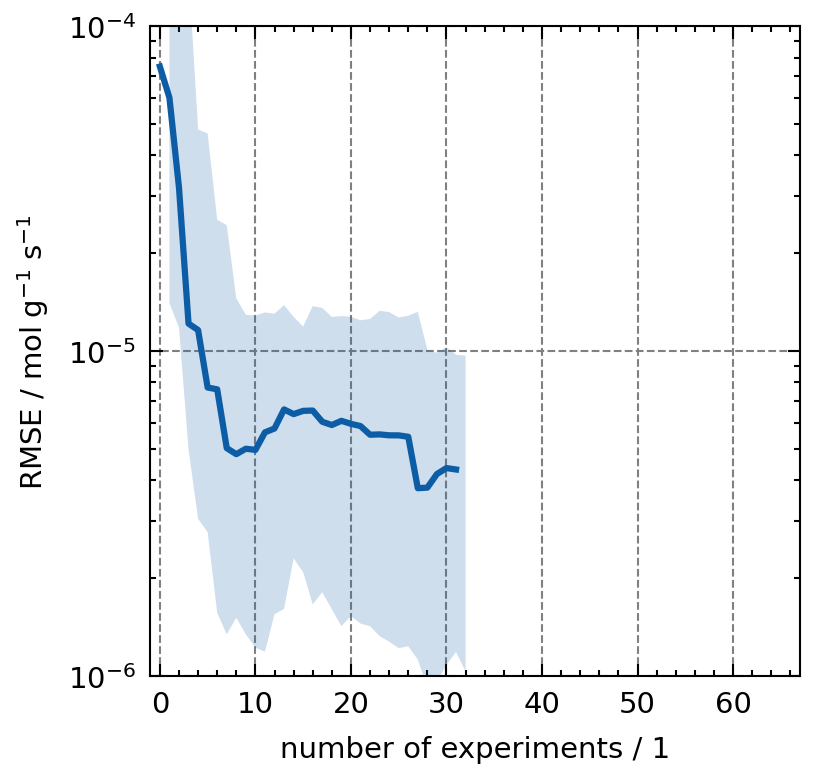

In [19]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(1e-6, 1e-4),
    xlim=(-1, 67),
)

ax.plot(
    np.median(RMSEs, axis=1),
    # label=label,
)
ax.fill_between(
    np.arange(1, len(RMSEs) + 1),
    np.quantile(RMSEs, 0.025, axis=1),
    np.quantile(RMSEs, 0.975, axis=1),
    alpha=0.2,
    ls="--",
    # edgecolor="gray",
)
# ax.legend(frameon=True)

## Total information gain

Total information gain of model $i$ with respect to the prior,

$$\mathrm{IG}_i = \mathrm{KL}\big(p(\theta \mid D_i)\,\|\,p(\theta)\big)$$

over the **joint** 9-dimensional parameter vector — not a sum of marginals.

The inference-free trick used by the acquisition does not transfer here: for a
*realised* gain the posterior does not cancel, and

$$\mathrm{KL}\big(p(\theta\mid D)\,\|\,p(\theta)\big)=\mathbb{E}_{p(\theta\mid D)}\big[\log p(D\mid\theta)\big]-\log p(D)$$

needs the evidence $\log p(D)$. But the datasets here are **nested**, so the
evidence ratio telescopes into one-step predictive densities,

$$\frac{p(D_k)}{p(D_{k-1})}=\mathbb{E}_{p(\theta\mid D_{k-1})}\big[p(y_k\mid\theta,x_k)\big],$$

each a single Monte Carlo average over a trace we already have. That makes
$\log p(D_i)$ exact up to Monte Carlo error, so the gain below involves **no
density estimation and no Gaussian or copula assumption**.

In [20]:
from scipy.special import logsumexp

PARAM_ORDER = (
    "k0",
    "Ea_k",
    "A_oh",
    "dH_oh",
    "A_h2",
    "dH_h2",
    "A_mix",
    "dH_mix",
    "sigma_r",
)
# Matches the likelihood in bayesian_model: sigma_obs = sigma_r * |r_pred| + 1e-10
SIGMA_FLOOR = 1e-10


def param_draws(idata, group="posterior", thin=1):
    """Stack chain/draw into an (M, 9) float64 array with columns in PARAM_ORDER."""
    stacked = az.extract(
        idata, group=group, var_names=list(PARAM_ORDER), num_samples=None
    )
    theta = np.stack(
        [np.asarray(stacked[v].values, dtype=np.float64).ravel() for v in PARAM_ORDER],
        axis=1,
    )
    return theta[::thin]


def obs_loglik(X, Y, theta):
    """(k, M) log-density of each observation under each parameter draw.

    Args:
        X: (k, 6) design rows [T, p, c2h, c2m, c2w, c2i]
        Y: (k,) observed rates
        theta: (M, 9) parameter draws ordered as PARAM_ORDER
    """
    cols = [jnp.asarray(X[:, j : j + 1]) for j in range(6)]
    p_i = calculate_partial_pressures(cols[1], cols[2], cols[3], cols[4], cols[5])
    r = np.asarray(
        kinetics_model(p_i, cols[0], *[jnp.asarray(theta[:, j]) for j in range(8)]),
        dtype=np.float64,
    )
    s = theta[:, 8][None, :] * np.abs(r) + SIGMA_FLOOR
    z = (Y[:, None] - r) / s
    return -0.5 * np.log(2.0 * np.pi * s**2) - 0.5 * z**2

In [21]:
def total_information_gain(X, Y, posterior_draws, prior_draws):
    """Total information gain KL( p(theta|D_i) || p(theta) ) for every iteration.

    Args:
        X: (n, 6) design matrix; row k is the condition of observation k
        Y: (n,) observations
        posterior_draws: list of length n, element k holding (M, 9) draws from
            p(theta | D_{k+1}) -- i.e. posterior_draws[k] corresponds to trace_{k+1}
        prior_draws: (M0, 9) draws from the prior, which plays the role of D_0

    Returns:
        dict of arrays indexed by iteration k = 0 .. n-1:
            ig            total gain vs the prior [nats]
            incremental   KL( p(theta|D_{k+1}) || p(theta|D_k) ) [nats]
            log_evidence  running log p(D_{k+1})
            log_pred      log predictive density of observation k+1 under the
                          previous posterior
            pred_ess      effective sample size behind log_pred; if this collapses
                          to a handful of draws that step's evidence is unreliable
    """
    n = len(posterior_draws)
    out = {k: [] for k in ("ig", "incremental", "log_evidence", "log_pred", "pred_ess")}

    log_evidence = 0.0  # log p(D_0) = 0, no data yet
    previous = prior_draws

    for k in range(n):
        # --- evidence increment: log E_{p(theta|D_k)}[ p(y_{k+1} | theta) ] ---
        ll_prev = obs_loglik(X[k : k + 1], Y[k : k + 1], previous)[0]
        log_pred = logsumexp(ll_prev) - np.log(len(ll_prev))
        log_evidence += log_pred

        # reliability of that average: ESS of the implied weights
        w = np.exp(ll_prev - ll_prev.max())
        pred_ess = w.sum() ** 2 / (w**2).sum()

        # --- E_{p(theta|D_{k+1})}[ log p(D_{k+1} | theta) ] ---
        theta = posterior_draws[k]
        mean_loglik = obs_loglik(X[: k + 1], Y[: k + 1], theta).sum(axis=0).mean()

        # step-wise gain KL( p(theta|D_{k+1}) || p(theta|D_k) ), computed directly
        incremental = obs_loglik(X[k : k + 1], Y[k : k + 1], theta)[0].mean() - log_pred

        out["ig"].append(mean_loglik - log_evidence)
        out["incremental"].append(incremental)
        out["log_evidence"].append(log_evidence)
        out["log_pred"].append(log_pred)
        out["pred_ess"].append(pred_ess)

        previous = theta

    return {key: np.asarray(val) for key, val in out.items()}

In [22]:
THIN = 4  # 32000 -> 8000 draws per trace; ample, and keeps the arrays small

posterior_draws = [param_draws(idata, thin=THIN) for idata in idatas]
prior_draws = param_draws(sample_prior(num_samples=32768), group="prior")

ig_res = total_information_gain(
    proposals,
    np.asarray(r_obs).ravel(),
    posterior_draws,
    prior_draws,
)

print(f"{'i':>3} {'total IG':>10} {'incremental':>12} {'pred ESS':>9}")
for k in range(len(posterior_draws)):
    print(
        f"{k:3d} {ig_res['ig'][k]:10.3f} {ig_res['incremental'][k]:12.3f} "
        f"{ig_res['pred_ess'][k]:9.0f}"
    )

# Sanity check: every evidence increment must rest on more than a handful of draws.
weak = np.flatnonzero(ig_res["pred_ess"] < 50)
if weak.size:
    print(
        f"\nWARNING: low predictive ESS at iterations {weak.tolist()} -- "
        f"those evidence terms are unreliable, raise the trace draw count or lower THIN."
    )
else:
    print(
        f"\nAll evidence increments well resolved (min ESS {ig_res['pred_ess'].min():.0f})."
    )

  i   total IG  incremental  pred ESS
  0      3.622        3.622       496
  1      6.808        3.076       235
  2      9.855        2.978       290
  3     11.733        2.206       452
  4     13.662        1.542      1075
  5     16.209        1.775       817
  6     18.093        1.431      1172
  7     20.123        1.323       548
  8     20.215        0.711      2868
  9     19.247        0.542      3756
 10     19.396        0.460      4132
 11     19.836        0.356      4885
 12     19.063        0.915      2459
 13     20.026        0.165      6130
 14     20.875        0.135      6384
 15     19.235        2.179       585
 16     19.916        0.081      7013
 17     20.508        0.113      6655
 18     20.099        0.539      3548
 19     20.623        0.063      7170
 20     20.785        0.161      6193
 21     20.868        0.175      5981
 22     19.711        0.882      1993
 23     20.165        0.062      7267
 24     20.515        0.093      6753
 25     20.3

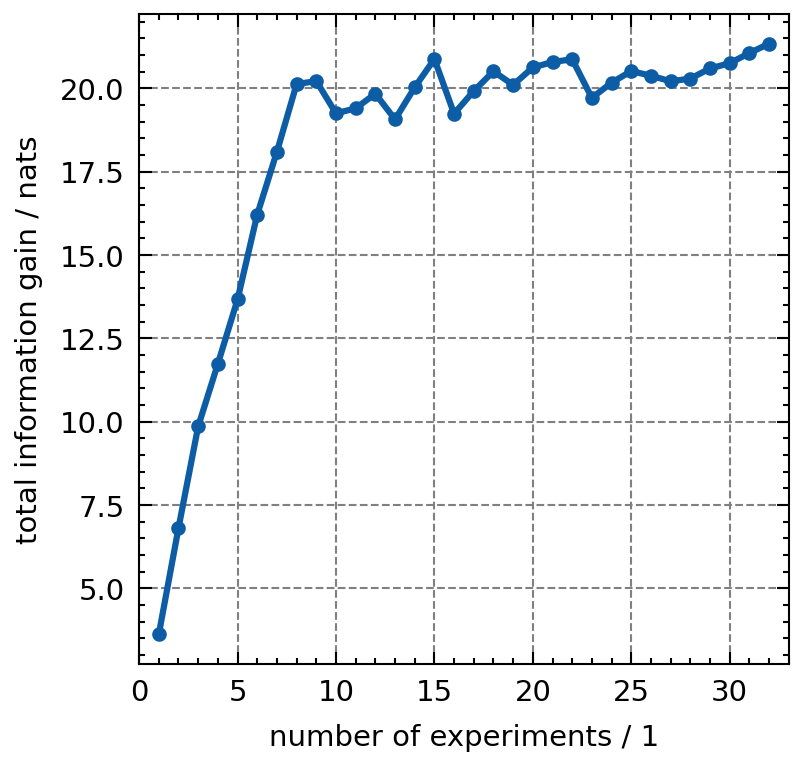

In [23]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"total information gain / nats",
    xlim=(0, len(ig_res["ig"]) + 1),
)

n_exp = np.arange(1, len(ig_res["ig"]) + 1)
ax.plot(n_exp, ig_res["ig"], marker="o", ms=2.5)

# Mark the iterations where the gain drops. This is not an error: an observation
# that contradicts the current posterior forces it to widen, which genuinely
# reduces KL from the prior. Those steps coincide with the most surprising data.
# drops = np.flatnonzero(np.diff(ig_res["ig"], prepend=0.0) < 0)
# if drops.size:
#     ax.scatter(
#         n_exp[drops],
#         ig_res["ig"][drops],
#         marker="v",
#         s=14,
#         color="tab:red",
#         zorder=5,
#         label="gain decreased",
#     )
#     ax.legend(frameon=True)

# plt.savefig("figures/KinFit_K_total_IG.png")
# plt.savefig("figures/KinFit_K_total_IG.svg")
# plt.savefig("figures/KinFit_K_total_IG.pdf")
# plt.show()